In [1]:
pip install pm4py

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import pm4py



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




In [24]:
df = pd.read_csv("cleaned_data")

In [25]:
df

,case_id,activity,timestamp,department,resource
0,HOSP_0001,Patient Registration,2026-03-23 08:54:00,Front Desk,Registration Clerk
1,HOSP_0001,Initial Triage,2026-03-23 09:14:00,Emergency/Triage,Triage Nurse
2,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00,Outpatient,Doctor
3,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00,Outpatient,Doctor
4,HOSP_0001,Payment Completed,2026-03-23 09:56:00,Billing,Billing Clerk
...,...,...,...,...,...
948,HOSP_0100,Initial Triage,2026-03-22 16:43:00,Emergency/Triage,Triage Nurse
949,HOSP_0100,Doctor Consultation,2026-03-22 16:47:00,Outpatient,Doctor
950,HOSP_0100,Treatment/Prescription,2026-03-22 16:55:00,Outpatient,Doctor
951,HOSP_0100,Payment Completed,2026-03-22 17:12:00,Billing,Billing Clerk


In [5]:
log = pm4py.format_dataframe(df, case_id = 'case_id', activity_key = 'activity', timestamp_key = 'timestamp')

In [6]:
log.head()

,case_id,activity,timestamp,department,resource,case:concept:name,concept:name,time:timestamp,@@index,@@case_index
0,HOSP_0001,Patient Registration,2026-03-23 08:54:00+00:00,Front Desk,Registration Clerk,HOSP_0001,Patient Registration,2026-03-23 08:54:00+00:00,0,0
1,HOSP_0001,Initial Triage,2026-03-23 09:14:00+00:00,Emergency/Triage,Triage Nurse,HOSP_0001,Initial Triage,2026-03-23 09:14:00+00:00,1,0
2,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00+00:00,Outpatient,Doctor,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00+00:00,2,0
3,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00+00:00,Outpatient,Doctor,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00+00:00,3,0
4,HOSP_0001,Payment Completed,2026-03-23 09:56:00+00:00,Billing,Billing Clerk,HOSP_0001,Payment Completed,2026-03-23 09:56:00+00:00,4,0


In [7]:
start_activity = pm4py.get_start_activities(log)
end_activity = pm4py.get_end_activities(log)
print("start_activity: ",start_activity)
print("end_activity: ",end_activity)

start_activity:  {'Patient Registration': 100}
end_activity:  {'Patient Discharged': 69, 'Discharge Processed': 31}


In [30]:
activity_count = df.groupby('activity')['activity'].value_counts()

In [32]:
activity_count.sort_values(ascending=False)

activity
Patient Registration           100
Initial Triage                 100
Doctor Consultation            100
Treatment/Prescription          69
Payment Completed               69
Patient Discharged              69
Lab Results Available           60
Sample Collected                60
Lab Test Ordered                60
Doctor Reviews Results          60
Admission Decision              31
Discharge Processed             31
Bed Assigned                    31
Treatment Completed             31
Patient Transferred to Ward     31
Imaging Ordered                 14
Imaging Completed               14
Doctor Reviews Imaging          14
Repeat Doctor Consultation       9
Name: count, dtype: int64

In [33]:
dfg, first_stage, last_stage = pm4py.discover_dfg(log)

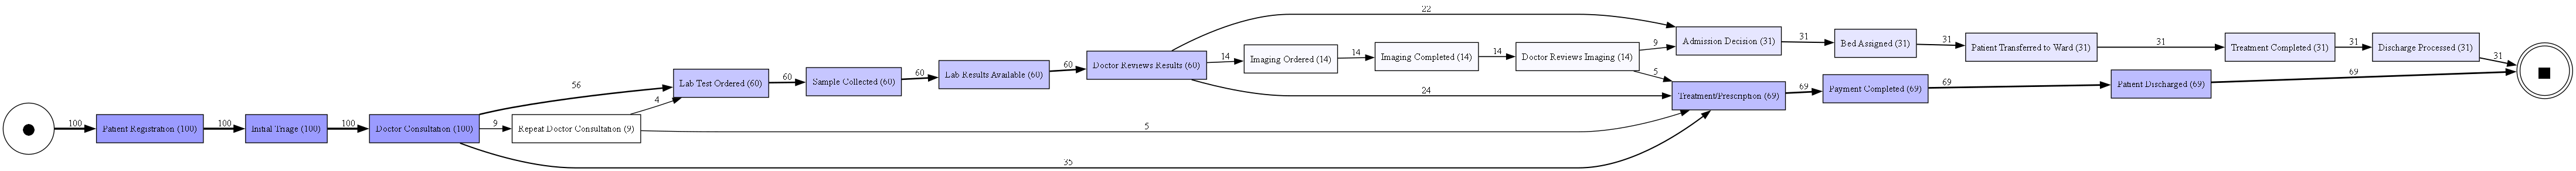

In [34]:
pm4py.view_dfg(dfg, first_stage, last_stage)

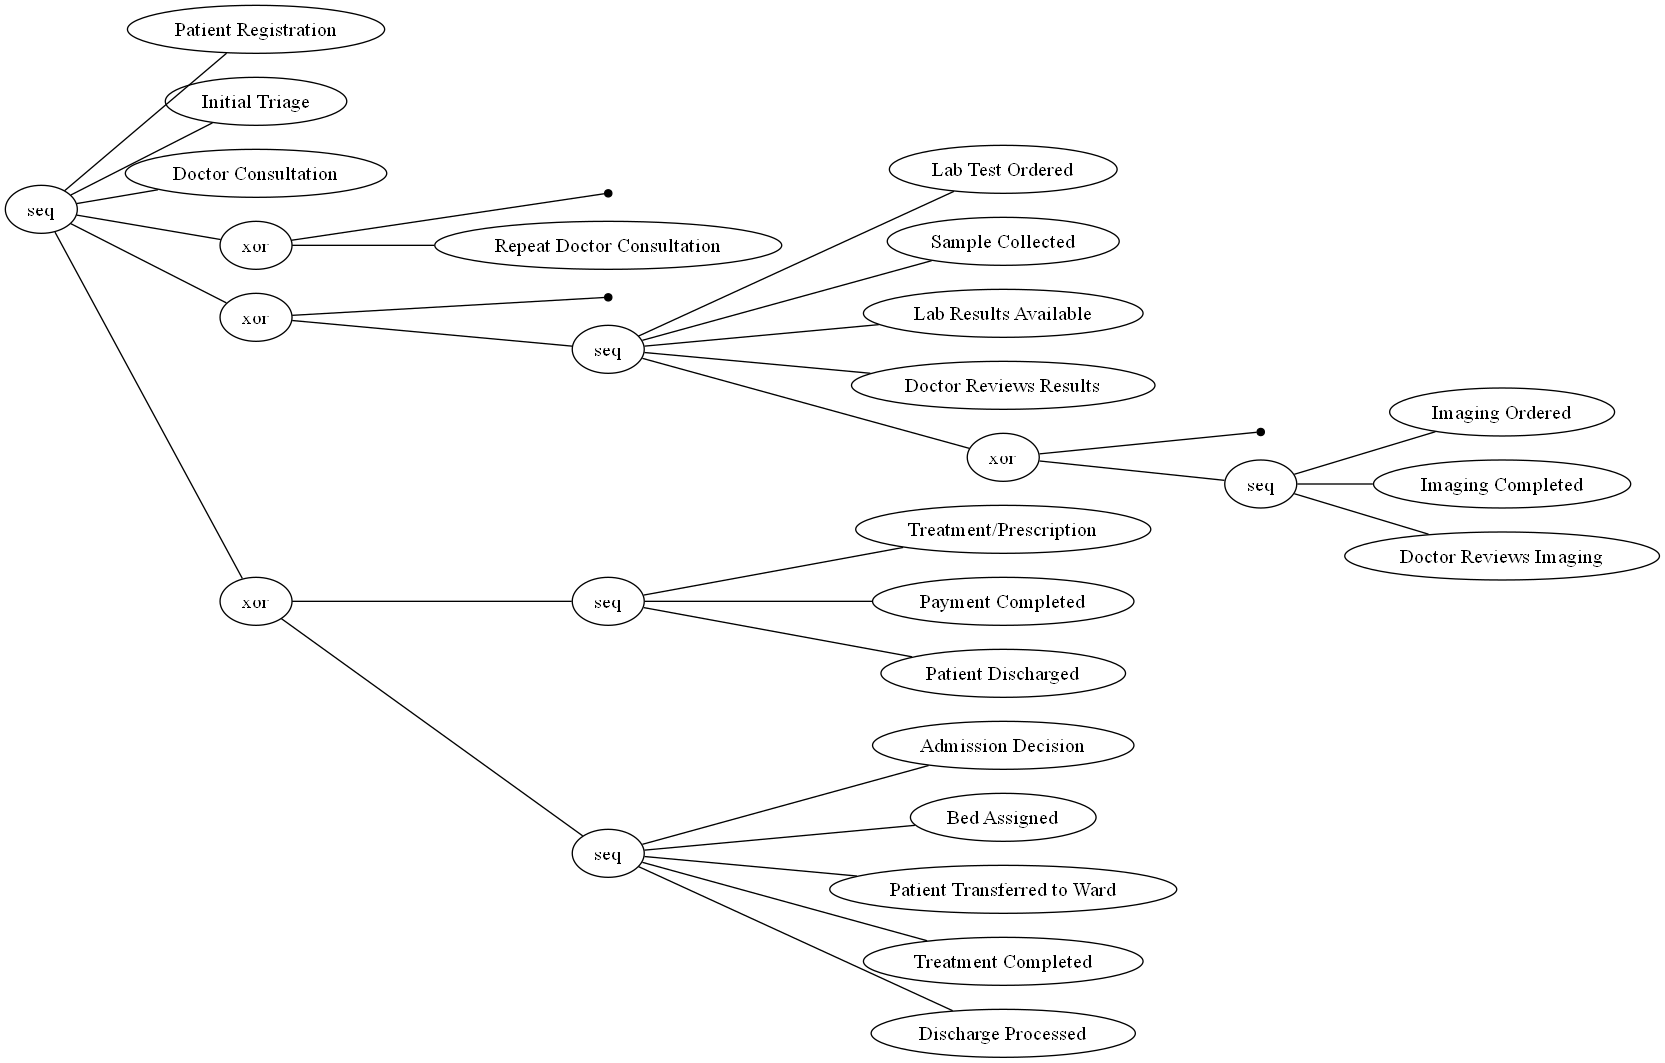

In [10]:
tree = pm4py.discover_process_tree_inductive(log)
pm4py.view_process_tree(tree)

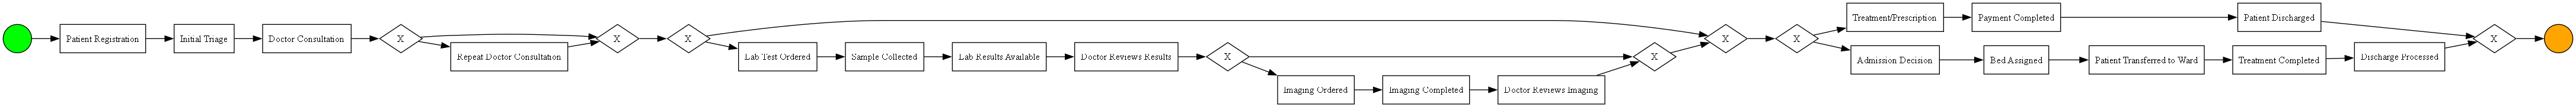

In [11]:
model = pm4py.discover_bpmn_inductive(log)
pm4py.view_bpmn(model)

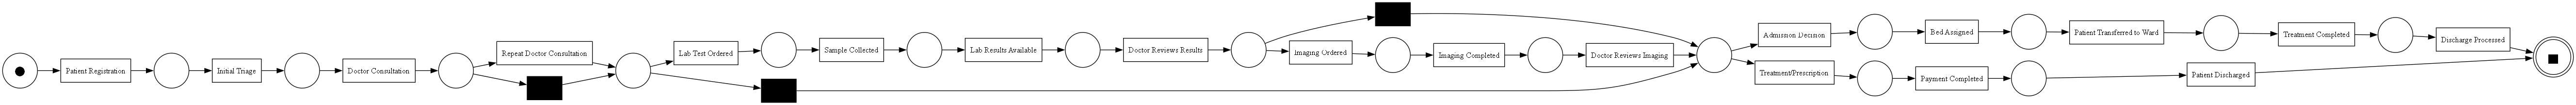

In [36]:
net, im, fm = pm4py.discover_petri_net_inductive(log)
pm4py.view_petri_net(net, im, fm)

In [12]:
df

,case_id,activity,timestamp,department,resource,case:concept:name,concept:name,time:timestamp
0,HOSP_0001,Patient Registration,2026-03-23 08:54:00,Front Desk,Registration Clerk,HOSP_0001,Patient Registration,2026-03-23 08:54:00
1,HOSP_0001,Initial Triage,2026-03-23 09:14:00,Emergency/Triage,Triage Nurse,HOSP_0001,Initial Triage,2026-03-23 09:14:00
2,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00,Outpatient,Doctor,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00
3,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00,Outpatient,Doctor,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00
4,HOSP_0001,Payment Completed,2026-03-23 09:56:00,Billing,Billing Clerk,HOSP_0001,Payment Completed,2026-03-23 09:56:00
...,...,...,...,...,...,...,...,...
948,HOSP_0100,Initial Triage,2026-03-22 16:43:00,Emergency/Triage,Triage Nurse,HOSP_0100,Initial Triage,2026-03-22 16:43:00
949,HOSP_0100,Doctor Consultation,2026-03-22 16:47:00,Outpatient,Doctor,HOSP_0100,Doctor Consultation,2026-03-22 16:47:00
950,HOSP_0100,Treatment/Prescription,2026-03-22 16:55:00,Outpatient,Doctor,HOSP_0100,Treatment/Prescription,2026-03-22 16:55:00
951,HOSP_0100,Payment Completed,2026-03-22 17:12:00,Billing,Billing Clerk,HOSP_0100,Payment Completed,2026-03-22 17:12:00


In [13]:
df['next_activity'] = df.groupby('case_id')['activity'].shift(-1)

In [14]:
df

,case_id,activity,timestamp,department,resource,case:concept:name,concept:name,time:timestamp,next_activity
0,HOSP_0001,Patient Registration,2026-03-23 08:54:00,Front Desk,Registration Clerk,HOSP_0001,Patient Registration,2026-03-23 08:54:00,Initial Triage
1,HOSP_0001,Initial Triage,2026-03-23 09:14:00,Emergency/Triage,Triage Nurse,HOSP_0001,Initial Triage,2026-03-23 09:14:00,Doctor Consultation
2,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00,Outpatient,Doctor,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00,Treatment/Prescription
3,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00,Outpatient,Doctor,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00,Payment Completed
4,HOSP_0001,Payment Completed,2026-03-23 09:56:00,Billing,Billing Clerk,HOSP_0001,Payment Completed,2026-03-23 09:56:00,Patient Discharged
...,...,...,...,...,...,...,...,...,...
948,HOSP_0100,Initial Triage,2026-03-22 16:43:00,Emergency/Triage,Triage Nurse,HOSP_0100,Initial Triage,2026-03-22 16:43:00,Doctor Consultation
949,HOSP_0100,Doctor Consultation,2026-03-22 16:47:00,Outpatient,Doctor,HOSP_0100,Doctor Consultation,2026-03-22 16:47:00,Treatment/Prescription
950,HOSP_0100,Treatment/Prescription,2026-03-22 16:55:00,Outpatient,Doctor,HOSP_0100,Treatment/Prescription,2026-03-22 16:55:00,Payment Completed
951,HOSP_0100,Payment Completed,2026-03-22 17:12:00,Billing,Billing Clerk,HOSP_0100,Payment Completed,2026-03-22 17:12:00,Patient Discharged


In [15]:
df['next_activity_time'] = df.groupby('case_id')['timestamp'].shift(-1)

In [16]:
df.head(10)

,case_id,activity,timestamp,department,resource,case:concept:name,concept:name,time:timestamp,next_activity,next_activity_time
0,HOSP_0001,Patient Registration,2026-03-23 08:54:00,Front Desk,Registration Clerk,HOSP_0001,Patient Registration,2026-03-23 08:54:00,Initial Triage,2026-03-23 09:14:00
1,HOSP_0001,Initial Triage,2026-03-23 09:14:00,Emergency/Triage,Triage Nurse,HOSP_0001,Initial Triage,2026-03-23 09:14:00,Doctor Consultation,2026-03-23 09:19:00
2,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00,Outpatient,Doctor,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00,Treatment/Prescription,2026-03-23 09:40:00
3,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00,Outpatient,Doctor,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00,Payment Completed,2026-03-23 09:56:00
4,HOSP_0001,Payment Completed,2026-03-23 09:56:00,Billing,Billing Clerk,HOSP_0001,Payment Completed,2026-03-23 09:56:00,Patient Discharged,2026-03-23 10:00:00
5,HOSP_0001,Patient Discharged,2026-03-23 10:00:00,Outpatient,Nurse,HOSP_0001,Patient Discharged,2026-03-23 10:00:00,NaN,NaN
6,HOSP_0002,Patient Registration,2026-01-12 10:43:00,Front Desk,Registration Clerk,HOSP_0002,Patient Registration,2026-01-12 10:43:00,Initial Triage,2026-01-12 11:00:00
7,HOSP_0002,Initial Triage,2026-01-12 11:00:00,Emergency/Triage,Triage Nurse,HOSP_0002,Initial Triage,2026-01-12 11:00:00,Doctor Consultation,2026-01-12 11:21:00
8,HOSP_0002,Doctor Consultation,2026-01-12 11:21:00,Outpatient,Doctor,HOSP_0002,Doctor Consultation,2026-01-12 11:21:00,Treatment/Prescription,2026-01-12 11:32:00
9,HOSP_0002,Treatment/Prescription,2026-01-12 11:32:00,Outpatient,Doctor,HOSP_0002,Treatment/Prescription,2026-01-12 11:32:00,Payment Completed,2026-01-12 11:35:00


In [17]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 953 entries, 0 to 952
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   case_id             953 non-null    object
 1   activity            953 non-null    object
 2   timestamp           953 non-null    object
 3   department          953 non-null    object
 4   resource            953 non-null    object
 5   case:concept:name   953 non-null    object
 6   concept:name        953 non-null    object
 7   time:timestamp      953 non-null    object
 8   next_activity       853 non-null    object
 9   next_activity_time  853 non-null    object
dtypes: object(10)
memory usage: 74.6+ KB


In [18]:
df['next_activity_time'] = pd.to_datetime(df['next_activity_time'])

In [19]:
df['timestamp'] = pd.to_datetime(df['timestamp'])

In [20]:
df['waiting_time'] = (df['next_activity_time'] - df['timestamp']).dt.total_seconds()/60

In [21]:
df

,case_id,activity,timestamp,department,resource,case:concept:name,concept:name,time:timestamp,next_activity,next_activity_time,waiting_time
0,HOSP_0001,Patient Registration,2026-03-23 08:54:00,Front Desk,Registration Clerk,HOSP_0001,Patient Registration,2026-03-23 08:54:00,Initial Triage,2026-03-23 09:14:00,20.0
1,HOSP_0001,Initial Triage,2026-03-23 09:14:00,Emergency/Triage,Triage Nurse,HOSP_0001,Initial Triage,2026-03-23 09:14:00,Doctor Consultation,2026-03-23 09:19:00,5.0
2,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00,Outpatient,Doctor,HOSP_0001,Doctor Consultation,2026-03-23 09:19:00,Treatment/Prescription,2026-03-23 09:40:00,21.0
3,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00,Outpatient,Doctor,HOSP_0001,Treatment/Prescription,2026-03-23 09:40:00,Payment Completed,2026-03-23 09:56:00,16.0
4,HOSP_0001,Payment Completed,2026-03-23 09:56:00,Billing,Billing Clerk,HOSP_0001,Payment Completed,2026-03-23 09:56:00,Patient Discharged,2026-03-23 10:00:00,4.0
...,...,...,...,...,...,...,...,...,...,...,...
948,HOSP_0100,Initial Triage,2026-03-22 16:43:00,Emergency/Triage,Triage Nurse,HOSP_0100,Initial Triage,2026-03-22 16:43:00,Doctor Consultation,2026-03-22 16:47:00,4.0
949,HOSP_0100,Doctor Consultation,2026-03-22 16:47:00,Outpatient,Doctor,HOSP_0100,Doctor Consultation,2026-03-22 16:47:00,Treatment/Prescription,2026-03-22 16:55:00,8.0
950,HOSP_0100,Treatment/Prescription,2026-03-22 16:55:00,Outpatient,Doctor,HOSP_0100,Treatment/Prescription,2026-03-22 16:55:00,Payment Completed,2026-03-22 17:12:00,17.0
951,HOSP_0100,Payment Completed,2026-03-22 17:12:00,Billing,Billing Clerk,HOSP_0100,Payment Completed,2026-03-22 17:12:00,Patient Discharged,2026-03-22 17:28:00,16.0


In [22]:
more_time_taken = df.groupby('next_activity')['waiting_time'].agg(['max', 'mean', 'min'])

In [23]:
more_time_taken.sort_values(by=['mean'], ascending=False)

,max,mean,min
next_activity,,,
Repeat Doctor Consultation,25.0,16.666667,6.0
Initial Triage,25.0,15.880000,4.0
Payment Completed,25.0,15.536232,3.0
Doctor Reviews Imaging,25.0,15.357143,5.0
Admission Decision,25.0,15.225806,3.0
Lab Results Available,25.0,15.150000,3.0
Imaging Ordered,24.0,15.000000,3.0
Treatment/Prescription,25.0,14.710145,3.0
Patient Discharged,25.0,14.579710,3.0
